# T37 -- Phase 3: spatial clustering of candidates on real data

Clusters the real 280 T36-scored candidates into distinct spatial regions (DBSCAN,
`eps_m=2000.0` reused from T31's own `spatial_matching_radius_m`, `min_samples=1` so
no candidate is dropped). Replaces the previous "top 10 nearly-identical points"
behavior with a small set of ranked, distinct CLUSTERS.

**`source_score` remains an evidence-ranking score, not a probability -- the top-
ranked cluster is NOT proven to be the actual physical source.**

In [1]:
import os, sys, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from iste.ensemble_run import EnsembleRunRecords
from iste.analysis_grid import generate_analysis_grid
from iste.candidate_extraction import CandidateExtractionConfig, find_candidate_peaks
from iste.kdtree_neighborhood import build_particle_neighborhood_index
from iste.particle_query import query_particle_slice
from iste.support_features import SupportFeatureConfig, compute_support_map
from iste.phase3_composite import DEFAULT_WEIGHTS, compute_source_scores_for_candidates
from iste.phase3_clustering import DEFAULT_EPS_M, cluster_candidates

## 1. Load real Stage III result + regenerate candidates with support grids

In [2]:
history_path = os.path.join(REPO_ROOT, "results", "actual_data", "stage3_particle_history.npz")
cached = np.load(history_path, allow_pickle=True)

def _none_if_empty(arr):
    return None if arr.size == 0 else arr

records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
t_obs = np.datetime64(np.max(records.timestamp), "ns")
grid = generate_analysis_grid(t_obs, window_hours=72.0, interval_hours=1.0)
historical_timestamps = grid[1:]
print(f"loaded {records.n_records} real rows; {len(historical_timestamps)} historical timestamps")

loaded 240024 real rows; 72 historical timestamps


In [3]:
spill_data = json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
obs_bbox = spill["bounding_box"]
valid_mask = records.valid
lat_min = min(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].min()))
lat_max = max(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].max()))
lon_min = min(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].min()))
lon_max = max(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()
extraction_config = CandidateExtractionConfig(peak_neighborhood_cells=5, min_separation_m=1500.0, core_radius_m=1000.0)
lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)

t0 = time.time()
all_candidates = []
support_grids_by_t_s = {}
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(
        index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config,
    )
    grid_vals = np.array([sf.support for sf in support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
    support_grids_by_t_s[np.datetime64(t_s, "ns")] = grid_vals
    all_candidates.extend(find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config))
t1 = time.time()
print(f"regenerated {len(all_candidates)} real candidates in {t1-t0:.1f}s")

regenerated 280 real candidates in 79.6s


## 2. Compute T36 DEFAULT composite scores (reused, not recomputed differently)

In [4]:
t2 = time.time()
default_scores = compute_source_scores_for_candidates(
    records, all_candidates, support_grids_by_t_s, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M,
    weights=DEFAULT_WEIGHTS,
)
t3 = time.time()
print(f"computed T36 source scores for {len(default_scores)} real candidates in {t3-t2:.1f}s")

computed T36 source scores for 280 real candidates in 46.0s


## 3. Cluster the real candidates

In [5]:
print(f"DEFAULT_EPS_M = {DEFAULT_EPS_M} m (reused from T31's spatial_matching_radius_m)")
clusters = cluster_candidates(all_candidates, default_scores, eps_m=DEFAULT_EPS_M)
print(f"{len(all_candidates)} raw candidates -> {len(clusters)} distinct spatial clusters")

n_members_total = sum(cl.n_members for cl in clusters)
assert n_members_total == len(all_candidates)
print(f"every candidate accounted for exactly once: confirmed ({n_members_total} == {len(all_candidates)})")

DEFAULT_EPS_M = 2000.0 m (reused from T31's spatial_matching_radius_m)
280 raw candidates -> 10 distinct spatial clusters
every candidate accounted for exactly once: confirmed (280 == 280)


## 4. Final ranked cluster table (top 10) -- replaces the previous near-duplicate top-10

In [6]:
top10_clusters = clusters[:10]
rows = []
for cl in top10_clusters:
    rows.append(dict(
        cluster_id=cl.cluster_id, n_members=cl.n_members,
        centroid_lat=round(cl.centroid_lat, 5), centroid_lon=round(cl.centroid_lon, 5),
        spatial_radius_m=round(cl.spatial_radius_m, 1),
        area_km2=round(cl.area_m2 / 1e6, 3) if cl.area_m2 is not None else None,
        total_particle_support=round(cl.total_particle_support, 1),
        n_distinct_timestamps=cl.n_distinct_timestamps,
        temporal_span_hours=round(cl.temporal_span_hours, 1),
        mean_normalized_kde=round(cl.mean_normalized_kde, 4),
        peak_normalized_kde=round(cl.peak_normalized_kde, 4),
        mean_convergence=round(cl.mean_convergence_score, 4),
        mean_dispersion=round(cl.mean_dispersion_score, 4),
        mean_ais=cl.mean_ais_score,
        peak_source_score=round(cl.peak_source_score, 4),
        mean_source_score=round(cl.mean_source_score, 4),
    ))
cluster_table = pd.DataFrame(rows)
print(cluster_table.to_string(index=False))

 cluster_id  n_members  centroid_lat  centroid_lon  spatial_radius_m  area_km2  total_particle_support  n_distinct_timestamps  temporal_span_hours  mean_normalized_kde  peak_normalized_kde  mean_convergence  mean_dispersion mean_ais  peak_source_score  mean_source_score
cluster0000        147      34.25934      35.41014           24439.1   276.237                 56840.0                     72                 71.0               0.6944               1.5438            0.4969           0.6924     None             1.4620             0.7429
cluster0002         83      34.33003      35.34287           10033.7    85.921                  3841.0                     34                 34.0               0.2048               0.6455            0.3540           0.2150     None             0.7383             0.4116
cluster0006         30      34.40575      35.54388            6301.1    28.462                    39.0                     15                 14.0               0.0057               0.044

In [7]:
print(clusters[0].confidence_uncertainty_note)

Confidence/uncertainty quantification is T38's own task (bootstrap/stability analysis), not yet implemented. This field intentionally reports no fabricated number; spatial_radius_m/n_members/temporal_span_hours are provided as the raw geometry T38 will need.


## 5. Cluster size distribution -- does this actually reduce near-duplicate redundancy?

n clusters: 10
cluster size distribution: min=1, max=147, mean=28.00, median=2.5
n singleton clusters (1 member): 4
n clusters with >=5 members: 4


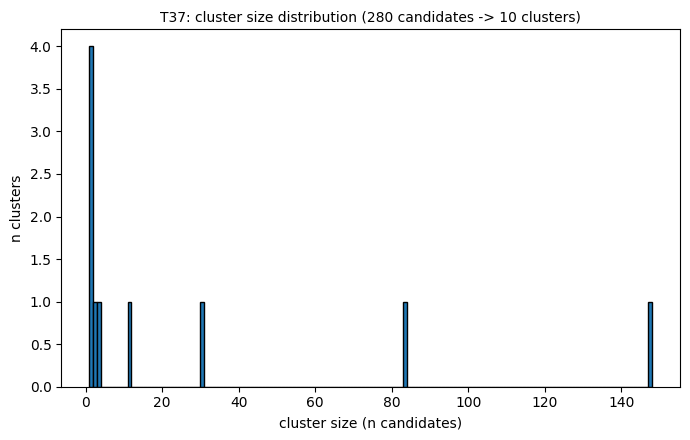

In [8]:
cluster_sizes = [cl.n_members for cl in clusters]
print(f"n clusters: {len(clusters)}")
print(f"cluster size distribution: min={min(cluster_sizes)}, max={max(cluster_sizes)}, "
      f"mean={np.mean(cluster_sizes):.2f}, median={np.median(cluster_sizes):.1f}")
print(f"n singleton clusters (1 member): {sum(1 for s in cluster_sizes if s == 1)}")
print(f"n clusters with >=5 members: {sum(1 for s in cluster_sizes if s >= 5)}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(cluster_sizes, bins=range(1, max(cluster_sizes) + 2), edgecolor="black")
ax.set_xlabel("cluster size (n candidates)"); ax.set_ylabel("n clusters")
ax.set_title(f"T37: cluster size distribution ({len(all_candidates)} candidates -> {len(clusters)} clusters)", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T37_cluster_size_distribution.png"), dpi=100)
plt.show()

## 6. Map of top-10 cluster centroids

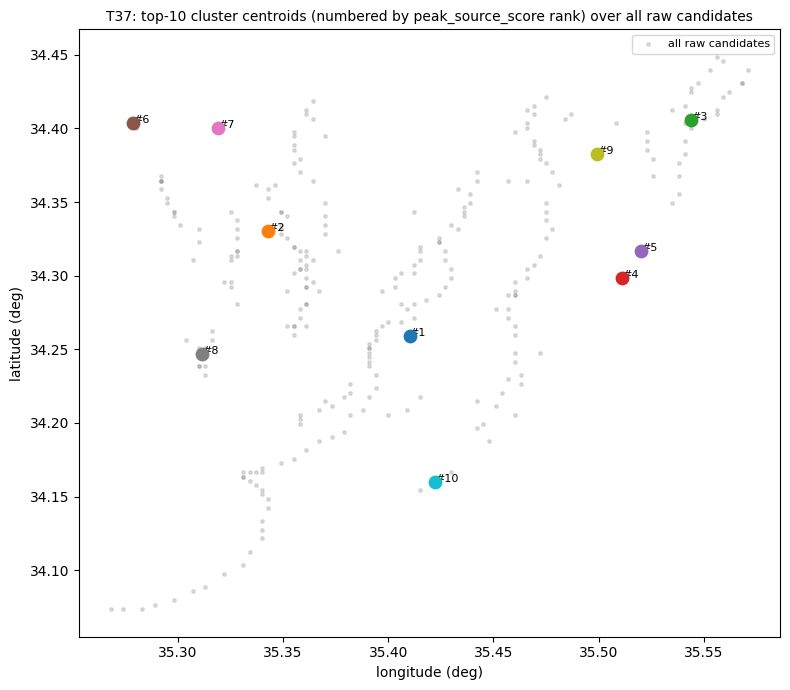

In [9]:
fig, ax = plt.subplots(figsize=(8, 7))
all_lats = [c.y_peak for c in all_candidates]
all_lons = [c.x_peak for c in all_candidates]
ax.scatter(all_lons, all_lats, s=6, alpha=0.25, color="gray", label="all raw candidates")
for rank, cl in enumerate(top10_clusters):
    ax.scatter([cl.centroid_lon], [cl.centroid_lat], s=80, zorder=5)
    ax.annotate(f"#{rank+1}", (cl.centroid_lon, cl.centroid_lat), fontsize=8)
ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")
ax.set_title("T37: top-10 cluster centroids (numbered by peak_source_score rank) over all raw candidates", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T37_top10_clusters_map.png"), dpi=100)
plt.show()

## Known limitations (T37 scope only)

- `eps_m=2000.0` is a documented, reused (not re-derived) PROTOTYPE/CONFIGURATION
  choice -- fully overridable.
- DBSCAN with `min_samples=1` is mathematically equivalent to single-linkage
  hierarchical clustering at the same distance threshold -- the choice of algorithm is
  not claimed to change the resulting grouping.
- `confidence_uncertainty_note` explicitly defers to T38 (not yet implemented) rather
  than fabricating a confidence number.
- Cluster-level `source_score` (`peak_source_score`) inherits every caveat already
  established for T36's per-candidate `source_score` -- an evidence-ranking score, not
  a probability, and not proof of source identity.
- No Stage III module, and no existing T14-T36 module, was modified.